<a href="https://colab.research.google.com/github/the-name-is-madhu/BIS_LAB/blob/main/1BM24CS154__Manufacturing_Job_Shop_Scheduling__Ant_colony_optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Deploying Ants to optimize factory scheduling path sequences...

=== Optimization Final Results Summary ===
Optimal Makespan Found: 10.0 hours
Best Operational Sequence Path: [1, 2, 0, 0, 0, 2, 1, 1, 2]


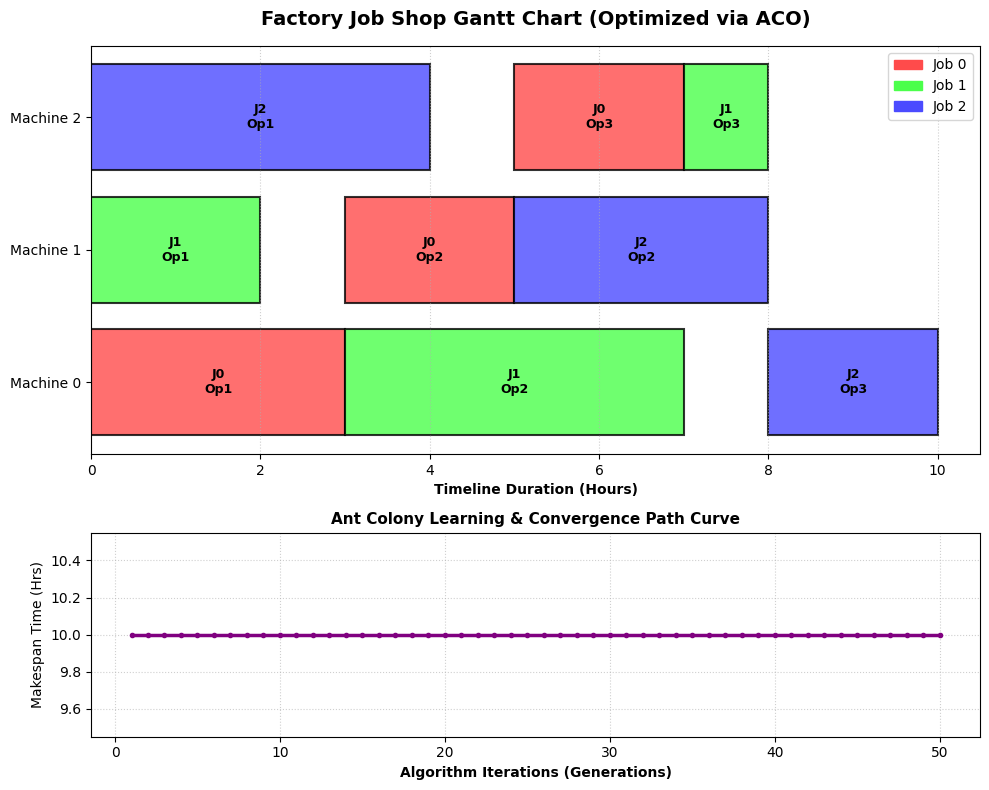

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import random

# =============================================================================
# 1. PROBLEM DEFINITION (Job Shop Matrix)
# =============================================================================
# For each job, list of tuples: (Machine ID, Processing Time in Hours)
# Example: Job 0 must go to Machine 0 for 3 hours, then Machine 1 for 2 hours...
JOBS_DATA = {
    0: [(0, 3), (1, 2), (2, 2)],
    1: [(1, 2), (0, 4), (2, 1)],
    2: [(2, 4), (1, 3), (0, 2)]
}

NUM_JOBS = len(JOBS_DATA)
NUM_MACHINES = 3
TOTAL_OPS = sum(len(ops) for ops in JOBS_DATA.values())

# =============================================================================
# 2. ACO PARAMETERS
# =============================================================================
NUM_ANTS = 20
ITERATIONS = 50
ALPHA = 1.0       # Importance of Pheromones (Memory)
BETA = 2.0        # Importance of Heuristic (Shortest Processing Time)
EVAPORATION = 0.2  # Scent decay rate (0.2 means 20% evaporates each round)
Q = 100           # Pheromone deposit reward multiplier

# Initialize Pheromone Matrix: [Job_ID][Op_Index] -> baseline presence
pheromone_matrix = np.ones((NUM_JOBS, NUM_MACHINES)) * 0.1

# =============================================================================
# 3. HELPER EVALUATION FUNCTIONS
# =============================================================================
def calculate_makespan(operation_sequence):
    """
    Takes an ordered sequence of job picks, simulates the factory timeline,
    and returns the total completion time (makespan) along with schedule schedules.
    """
    machine_free_time = np.zeros(NUM_MACHINES)
    job_next_free_time = np.zeros(NUM_JOBS)
    job_op_index = np.zeros(NUM_JOBS, dtype=int)

    # Track assignments for plotting: {job_id: [(machine, start, end), ...]}
    schedule_history = {j: [] for j in range(NUM_JOBS)}

    for job in operation_sequence:
        op_idx = job_op_index[job]
        machine, proc_time = JOBS_DATA[job][op_idx]

        # Job can start only after its previous step finishes AND the machine is empty
        start_time = max(job_next_free_time[job], machine_free_time[machine])
        end_time = start_time + proc_time

        # Update trackers
        machine_free_time[machine] = end_time
        job_next_free_time[job] = end_time
        job_op_index[job] += 1

        schedule_history[job].append((machine, start_time, end_time))

    return max(machine_free_time), schedule_history

# =============================================================================
# 4. CORE ACO OPTIMIZATION ENGINE
# =============================================================================
print("Deploying Ants to optimize factory scheduling path sequences...")

best_global_makespan = float('inf')
best_global_sequence = None
best_global_schedule = None
convergence_history = []

for iteration in range(ITERATIONS):
    ant_sequences = []
    ant_makespans = []

    for ant in range(NUM_ANTS):
        # Track how many operations have been scheduled for each job
        job_progress = np.zeros(NUM_JOBS, dtype=int)
        sequence = []

        while len(sequence) < TOTAL_OPS:
            # Determine which jobs still have unfinished steps remaining
            available_jobs = [j for j in range(NUM_JOBS) if job_progress[j] < len(JOBS_DATA[j])]

            probabilities = []
            for job in available_jobs:
                current_op = job_progress[job]
                machine, proc_time = JOBS_DATA[job][current_op]

                # Fetch memory trail value
                tau = pheromone_matrix[job, current_op]
                # Inverse processing time: lower duration means higher heuristic desirability
                eta = 1.0 / proc_time

                # ACO Decision Formula
                prob = (tau ** ALPHA) * (eta ** BETA)
                probabilities.append(prob)

            # Normalize probabilities to sum up to 1.0
            prob_sum = sum(probabilities)
            probabilities = [p / prob_sum for p in probabilities]

            # Ant chooses the next job based on calculated odds
            chosen_job = random.choices(available_jobs, weights=probabilities, k=1)[0]
            sequence.append(chosen_job)
            job_progress[chosen_job] += 1

        # Calculate how well this ant's sequence performed
        makespan, schedule = calculate_makespan(sequence)
        ant_sequences.append(sequence)
        ant_makespans.append(makespan)

        # Record Global Champion Tracker
        if makespan < best_global_makespan:
            best_global_makespan = makespan
            best_global_sequence = sequence
            best_global_schedule = schedule

    # --- PHEROMONE MATRIX UPDATE PHASE ---
    # 1. Evaporation step (decay everywhere)
    pheromone_matrix *= (1.0 - EVAPORATION)

    # 2. Reward step (add scent along paths constructed by the ants)
    for seq, m_span in zip(ant_sequences, ant_makespans):
        reward = Q / m_span
        temp_progress = np.zeros(NUM_JOBS, dtype=int)
        for job in seq:
            op = temp_progress[job]
            pheromone_matrix[job, op] += reward
            temp_progress[job] += 1

    convergence_history.append(best_global_makespan)

# =============================================================================
# 5. TERMINAL TERMINAL SUMMARY & PLOTTING
# =============================================================================
print("\n=== Optimization Final Results Summary ===")
print(f"Optimal Makespan Found: {best_global_makespan} hours")
print(f"Best Operational Sequence Path: {best_global_sequence}")

# Generate Manufacturing Gantt Chart Visual Layout
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), gridspec_kw={'height_ratios': [2, 1]})

colors = ['#FF4B4B', '#4BFF4B', '#4B4BFF'] # Color assigned unique to each Job

# Format Top Chart: Machine Timelines
for job_id, operations in best_global_schedule.items():
    for op_num, (machine, start, end) in enumerate(operations):
        duration = end - start
        ax1.barh(machine, duration, left=start, align='center', alpha=0.8,
                 color=colors[job_id], edgecolor='black', linewidth=1.5)
        ax1.text(start + duration/2, machine, f"J{job_id}\nOp{op_num+1}",
                 ha='center', va='center', color='black', fontweight='bold', fontsize=9)

ax1.set_yticks(range(NUM_MACHINES))
ax1.set_yticklabels([f"Machine {m}" for m in range(NUM_MACHINES)])
ax1.set_xlabel("Timeline Duration (Hours)", fontweight='bold')
ax1.set_title("Factory Job Shop Gantt Chart (Optimized via ACO)", fontsize=14, fontweight='bold', pad=15)
ax1.grid(True, axis='x', linestyle=':', alpha=0.6)

# Custom Legend Handles
legend_handles = [plt.Rectangle((0,0),1,1, color=colors[i]) for i in range(NUM_JOBS)]
ax1.legend(legend_handles, [f"Job {i}" for i in range(NUM_JOBS)], loc='upper right')

# Format Bottom Chart: Convergence Proof
ax2.plot(range(1, ITERATIONS + 1), convergence_history, color='purple', linewidth=2.5, marker='o', markersize=3)
ax2.set_xlabel("Algorithm Iterations (Generations)", fontweight='bold')
ax2.set_ylabel("Makespan Time (Hrs)")
ax2.set_title("Ant Colony Learning & Convergence Path Curve", fontsize=11, fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()
